In [ ]:
from pathlib import Path
import pandas as pd
import torch

TRAINING_MODE = "binary"    # "qat" = Saintslab multibit weights; "binary" = Sakabe-style ±1 weights
QAT_BITS = 1                # Saintslab symmetric quantizer supports >= 2 bits
HIDDEN_SIZES = (16, 8)      # Change to (16, 8), (32,16), and (64,32) for the main experiment
SHUFFLED = True             # True = shuffled labels, False = original MNIST labels

# Read data
DATA_DIR = f"results/mnist_{HIDDEN_SIZES[0]}_{HIDDEN_SIZES[1]}_{TRAINING_MODE}_{QAT_BITS}bit{'_shuffled' if SHUFFLED else ''}"
data_dir = Path(DATA_DIR)

epoch_data_files = list(data_dir.glob("*.csv"))
inter = []
for f in epoch_data_files:
    data = pd.read_csv(f)
    data["model"] = int(f.stem)

    checkpoint = torch.load(
        data_dir / f"model_{int(f.stem):03d}.pt",
        map_location="cpu",
        weights_only=True
    )
    analysis_epochs = checkpoint["analysis_epochs"]

    if len(data) < 5:
        print(len(data))
    
    data = data[:analysis_epochs] # removing patience rows
    inter.append(data)

df_epochs = pd.concat(inter, ignore_index=True)




In [145]:
# Metric normalization according to section 4.4.1
import numpy as np
from scipy.ndimage import gaussian_filter1d 

def normalizer(values):
    values = values.to_numpy(dtype=float)
    values = np.log1p(values)
    values = gaussian_filter1d(values, sigma = 1)
    spread = values.max() - values.min()
    if not np.isfinite(spread) or np.isclose(spread, 0.0):
        return np.full(len(values), np.nan)
    values = (values - values.min()) / spread
    return values

metrics = ["train_loss", "val_loss", "bdm", "entropy"]
df_normalized = df_epochs.sort_values(["model", "epoch"]).copy()
df_normalized[metrics] = df_normalized.groupby("model")[metrics].transform(normalizer)


In [146]:
invalid_models = set(df_normalized.loc[~np.isfinite(df_normalized[metrics]).all(axis=1), "model"])
print("Models with nonfinite or constant normalized metrics:", len(invalid_models))
print("IDs:", sorted(invalid_models))

Models with nonfinite or constant normalized metrics: 1
IDs: [39]


In [147]:
# Manual inspection of invalid entropy models (after normalizing)

df_epochs[df_epochs["model"].isin(invalid_models)]

,Unnamed: 0,epoch,train_loss,val_loss,val_loss_epoch_end,bdm,entropy,model
342,0,1,3.921904,3.507660,3.507660,3411.367669,11.643856,39
343,1,2,3.471095,3.347994,3.347994,3397.860223,11.643856,39
344,2,3,3.456352,3.144344,3.144344,3383.773585,11.643856,39
345,3,4,2.981966,3.230301,3.230301,3357.473867,11.643856,39
346,4,5,2.774627,2.451962,2.451962,3352.676092,11.643856,39
347,5,6,2.685093,2.593251,2.593251,3363.429704,11.643856,39
348,6,7,2.578023,3.131935,3.131935,3359.316126,11.643856,39
349,7,8,2.653946,2.302585,2.302585,3356.789237,11.643856,39
350,8,9,2.526913,2.302585,2.302585,3356.782154,11.643856,39


In [148]:

results = []
excluded = []

for model_id, run in df_normalized.groupby("model"):
    run = run.sort_values("epoch")
    if len(run) < 5:
        excluded.append((model_id, "fewer than 5 analysis epochs"))
        continue
    if model_id in invalid_models:
        excluded.append((model_id, "nonfinite or constant metric"))
        continue

    row = {"model": int(model_id), "n_epochs": len(run)}
    for metric in ("bdm", "entropy"):
        row[f"{metric}_pearson"] = run["train_loss"].corr(run[metric], method="pearson")
        row[f"{metric}_spearman"] = run["train_loss"].corr(run[metric], method="spearman")
    if not np.isfinite([row[k] for k in row if k.endswith(("pearson", "spearman"))]).all():
        excluded.append((model_id, "undefined correlation"))
        continue
    results.append(row)

df_results_n5 = pd.DataFrame(results)
if df_results_n5.empty:
    raise ValueError("No valid models remained after the analysis-window and variance checks.")

# The signed, paired differences answer the main research question.
df_results_n5["delta_pearson"] = df_results_n5["bdm_pearson"] - df_results_n5["entropy_pearson"]
df_results_n5["delta_spearman"] = df_results_n5["bdm_spearman"] - df_results_n5["entropy_spearman"]
print("Valid runs:", len(df_results_n5), "/", df_epochs["model"].nunique())
print("Excluded:", excluded)

Valid runs: 49 / 50
Excluded: [(39, 'nonfinite or constant metric')]


In [149]:

N_BOOTSTRAP = 10_000
rng = np.random.default_rng(42)
columns = ["bdm_pearson", "entropy_pearson", "delta_pearson",
           "bdm_spearman", "entropy_spearman", "delta_spearman"]
array = df_results_n5[columns].to_numpy(dtype=float)
index = rng.integers(0, len(array), size=(N_BOOTSTRAP, len(array)))
bootstrap_means = array[index].mean(axis=1)
boot = {name: bootstrap_means[:, j] for j, name in enumerate(columns)}

for name in columns:
    ci = np.quantile(boot[name], [0.025, 0.975])
    mean = df_results_n5[name].mean()
    print(f"{name:19s} mean={mean:+.4f}  95% bootstrap CI=[{ci[0]:+.4f}, {ci[1]:+.4f}]")


bdm_pearson         mean=+0.9037  95% bootstrap CI=[+0.8466, +0.9508]
entropy_pearson     mean=+0.9372  95% bootstrap CI=[+0.8959, +0.9675]
delta_pearson       mean=-0.0334  95% bootstrap CI=[-0.0753, +0.0049]
bdm_spearman        mean=+0.8629  95% bootstrap CI=[+0.8020, +0.9146]
entropy_spearman    mean=+0.9261  95% bootstrap CI=[+0.8730, +0.9628]
delta_spearman      mean=-0.0632  95% bootstrap CI=[-0.1046, -0.0258]


In [150]:
print("Signed Pearson correlation difference:", df_results_n5["delta_pearson"].mean())
print("Signed Spearman correlation difference:", df_results_n5["delta_spearman"].mean())



Signed Pearson correlation difference: -0.03342607391963162
Signed Spearman correlation difference: -0.06318009421263897


In [152]:
# Get model IDs that passed the correlation analysis
valid_model_ids = set(df_results_n5["model"])

# Load accuracy only for valid models
test_accuracies = []

for p in sorted(data_dir.glob("model_*.pt")):
    model_id = int(p.stem.split("_")[-1])

    if model_id in valid_model_ids:
        checkpoint = torch.load(
            p,
            map_location="cpu",
            weights_only=True
        )
        test_accuracies.append(float(checkpoint["test_accuracy"]))

print("Mean accuracy:", np.mean(test_accuracies))
print("SD accuracy:", np.std(test_accuracies, ddof=1))
print("Accuracy sample size:", len(test_accuracies))

Mean accuracy: 0.09534897959183672
SD accuracy: 0.028513703740840265
Accuracy sample size: 49


In [153]:

plot_df = df_normalized[df_normalized["model"].isin(df_results_n5["model"])].copy()
metrics = ["train_loss", "val_loss", "bdm", "entropy"]
N_TRAJECTORY_BOOTSTRAP = 10_000
rng_traj = np.random.default_rng(123)
n_total = plot_df["model"].nunique()
boot_results = []

for epoch, runs in plot_df.groupby("epoch"):
    n_active = len(runs)
    if n_active < 5:
        continue
    values = runs[metrics].to_numpy(dtype=float)
    sampled = rng_traj.integers(0, n_active, size=(N_TRAJECTORY_BOOTSTRAP, n_active))
    boot_means = values[sampled].mean(axis=1)
    for j, metric in enumerate(metrics):
        ci = np.quantile(boot_means[:, j], [0.025, 0.975])
        boot_results.append({
            "epoch": epoch,
            "metric": metric,
            "mean": values[:, j].mean(),
            "lower": ci[0],
            "upper": ci[1],
            "n_active": n_active,
            "active_fraction": n_active / n_total,
        })

df_epoch_boot = pd.DataFrame(boot_results)
if df_epoch_boot.empty:
    print("No epoch has >=5 active valid runs; trajectory plot is not available.")

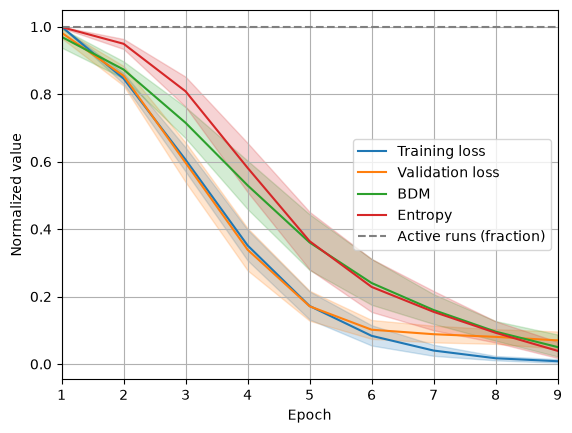

In [154]:
import matplotlib.pyplot as plt

if not df_epoch_boot.empty:
    fig, ax = plt.subplots()
    label_mapping = {
        "train_loss": "Training loss",
        "val_loss": "Validation loss",
        "bdm": "QuBD" if "_qat_" in str(data_dir) else "BDM",
        "entropy": "Entropy" if "_qat_" in str(data_dir) else "Entropy",
    }
    for metric in metrics:
        data = df_epoch_boot.loc[df_epoch_boot["metric"] == metric].sort_values("epoch")
        line, = ax.plot(data["epoch"], data["mean"], label=label_mapping[metric])
        ax.fill_between(data["epoch"], data["lower"], data["upper"],
                        color=line.get_color(), alpha=0.2)

    active = df_epoch_boot.drop_duplicates("epoch").sort_values("epoch")
    ax.plot(active["epoch"], active["active_fraction"], "--", color="gray", label="Active runs (fraction)")
    ax.set(xlabel="Epoch", ylabel="Normalized value")
    ax.legend()
    ax.margins(x=0)
    ax.grid()
    plt.show()

In [155]:
from torch import nn
from torch.nn import functional as F
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Modules from Saintslab
from scr.quantizer import UniformSymmetricQuantizer                                     # &&
from scr.utils_quantization import attach_weight_quantizers, toggle_quantization        # &&
from scr.qbdm import get_bitplanes, measure_complexity as saintslab_measure_complexity  # &&


def binarize(x):
   
    binary = torch.where(x > 0, 1.0, -1.0)
    clipped = x.clamp(-1, 1)
    return clipped + (binary - clipped).detach()


class BinaryLinear(nn.Linear):

    def forward(self, x):
        return F.linear(x, binarize(self.weight), self.bias)


class SakabeMLP(nn.Module):
    
    def __init__(self, hidden_sizes=(8, 4), mode="binary", qat_bits=4):
        super().__init__()
        h1, h2 = hidden_sizes                                          # &&
        if mode not in ("binary", "qat"):                              # &&
            raise ValueError(f"Unknown mode: {mode}")                  # &&
        Linear = BinaryLinear if mode == "binary" else nn.Linear       # &&
        self.fc1 = Linear(100, h1, bias=False)                         # &&
        self.bn1 = nn.BatchNorm1d(h1, affine=False)
        self.fc2 = Linear(h1, h2, bias=False)                          # &&
        self.bn2 = nn.BatchNorm1d(h2, affine=False)
        self.fc3 = Linear(h2, 10, bias=False)                          # &&
        self.mode = mode                                               # &&
        self.qat_bits = int(qat_bits) if mode == "qat" else 1          # &&

    def forward(self, x):
        x = x.flatten(start_dim=1)
        x = binarize(self.bn1(self.fc1(x)))
        x = binarize(self.bn2(self.fc2(x)))
        return self.fc3(x)


def build_model():    # &&
    model = SakabeMLP(HIDDEN_SIZES, mode=TRAINING_MODE, qat_bits=QAT_BITS).to(device)
    if TRAINING_MODE == "qat":
        if QAT_BITS < 2:
            raise ValueError("Saintslab's UniformSymmetricQuantizer requires QAT_BITS >= 2")
        # Faithful to Saintslab/QuBD train.py: attach BEFORE constructing optimizer.
        attach_weight_quantizers(
            model=model,
            exclude_layers=[],
            quantizer=UniformSymmetricQuantizer(bit_width=QAT_BITS),
            enabled=True,
        )
        toggle_quantization(model, enabled=True)
    return model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = build_model()
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


import numpy as np
import pandas as pd
import torch
from pathlib import Path
from contextlib import redirect_stdout
import io



# Choose which experiments to analyze
EXPERIMENTS = {
    "1-bit": Path(f"results/mnist_{HIDDEN_SIZES[0]}_{HIDDEN_SIZES[1]}_binary_1bit"),
    "2-bit": Path(f"results/mnist_{HIDDEN_SIZES[0]}_{HIDDEN_SIZES[1]}_qat_2bit"),
    "4-bit": Path(f"results/mnist_{HIDDEN_SIZES[0]}_{HIDDEN_SIZES[1]}_qat_4bit"),
}

N_BOOT = 10000
rng = np.random.default_rng(42)

# Reconstruct checkpoints on CPU
device = torch.device("cpu")

rows = []

for experiment, data_dir in EXPERIMENTS.items():

    if not data_dir.exists():
        print(f"Skipping {experiment}: directory not found")
        continue

    checkpoint_files = sorted(data_dir.glob("model_*.pt"))

    for path in checkpoint_files:

        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        TRAINING_MODE = checkpoint["mode"]
        QAT_BITS = checkpoint["qat_bits"]
        HIDDEN_SIZES = tuple(checkpoint["hidden_sizes"])

        # Suppress quantizer attachment messages
        with redirect_stdout(io.StringIO()):
            model = build_model()

        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        layer_levels = {}

        with torch.no_grad():

            for layer_name in ("fc1", "fc2", "fc3"):

                weights = getattr(
                    model, layer_name
                ).weight.detach().cpu()

                if TRAINING_MODE == "binary":
                    # BinaryLinear binarizes weights in forward()
                    levels = torch.where(
                        weights > 0, 1, -1
                    ).numpy().flatten()

                    possible_levels = [-1, 1]

                else:
                    # QAT: convert effective quantized weights
                    # back into their integer level indices
                    Q = 2 ** (QAT_BITS - 1) - 1

                    max_abs = weights.abs().max().item()
                    scale = max_abs / Q if max_abs > 0 else 1.0

                    levels = (
                        torch.round(weights / scale)
                        .clamp(-Q, Q)
                        .to(torch.int64)
                        .numpy()
                        .flatten()
                    )

                    possible_levels = list(range(-Q, Q + 1))

                layer_levels[layer_name] = levels

            # Combine all weights; larger layers contribute
            # proportionally more to the overall distribution
            layer_levels["All layers"] = np.concatenate([
                layer_levels["fc1"],
                layer_levels["fc2"],
                layer_levels["fc3"]
            ])

            for layer_name, levels in layer_levels.items():

                for level in possible_levels:

                    rows.append({
                        "experiment": experiment,
                        "model": int(path.stem.split("_")[-1]),
                        "layer": layer_name,
                        "level": level,
                        "fraction": np.mean(levels == level)
                    })


df_distributions = pd.DataFrame(rows)

# Bootstrap across independent models
summary_rows = []

for (experiment, layer, level), group in df_distributions.groupby(
    ["experiment", "layer", "level"]
):

    values = group["fraction"].to_numpy()
    n = len(values)

    bootstrap_means = rng.choice(
        values,
        size=(N_BOOT, n),
        replace=True
    ).mean(axis=1)

    lower, upper = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    summary_rows.append({
        "experiment": experiment,
        "layer": layer,
        "level": level,
        "N": n,
        "mean_pct": 100 * values.mean(),
        "CI_lower": 100 * lower,
        "CI_upper": 100 * upper
    })

df_summary = pd.DataFrame(summary_rows)

# Display overall distributions
overall = df_summary[
    df_summary["layer"] == "All layers"
].copy()

overall["Mean [95% CI]"] = overall.apply(
    lambda r: (
        f'{r["mean_pct"]:.2f}% '
        f'[{r["CI_lower"]:.2f}, {r["CI_upper"]:.2f}]'
    ),
    axis=1
)

display(
    overall[
        ["experiment", "level", "N", "Mean [95% CI]"]
    ]
    .sort_values(["experiment", "level"])
    .reset_index(drop=True)
)

,experiment,level,N,Mean [95% CI]
0,1-bit,-1,50,"50.12% [49.67, 50.58]"
1,1-bit,1,50,"49.88% [49.42, 50.33]"
2,2-bit,-1,50,"12.15% [11.76, 12.55]"
3,2-bit,0,50,"75.96% [75.41, 76.52]"
4,2-bit,1,50,"11.89% [11.58, 12.19]"
5,4-bit,-7,50,"0.90% [0.84, 0.97]"
6,4-bit,-6,50,"0.99% [0.92, 1.06]"
7,4-bit,-5,50,"1.82% [1.73, 1.91]"
8,4-bit,-4,50,"2.87% [2.75, 3.00]"
9,4-bit,-3,50,"4.74% [4.59, 4.90]"


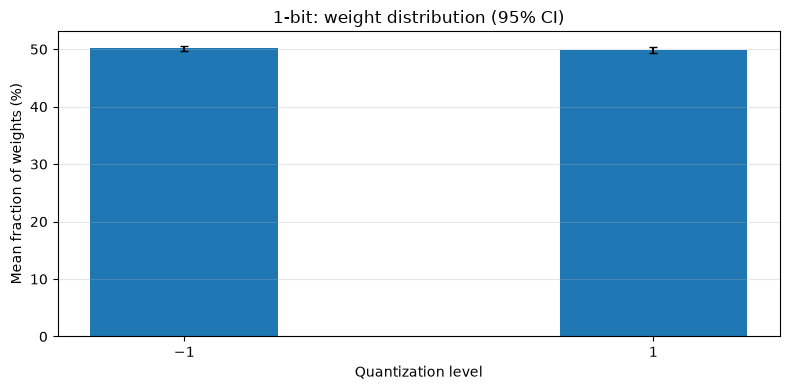

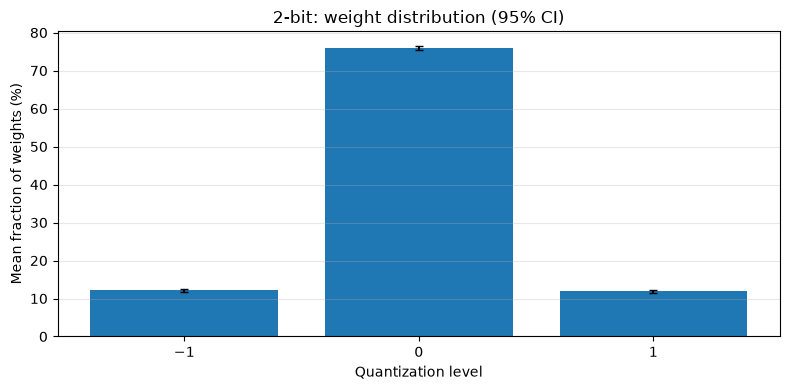

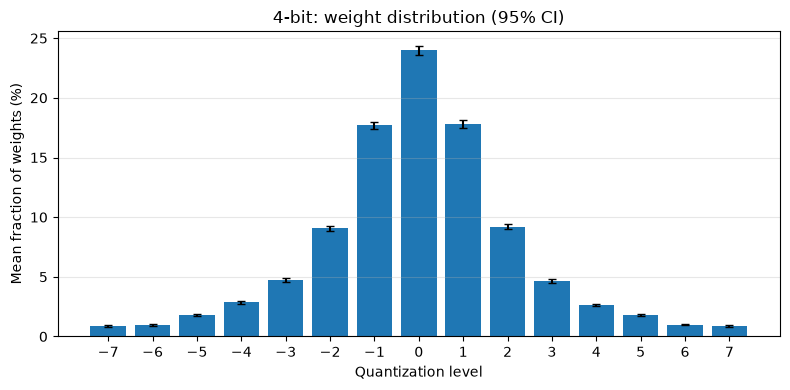

In [156]:
import matplotlib.pyplot as plt

for experiment in df_summary["experiment"].unique():

    subset = df_summary[
        (df_summary["experiment"] == experiment)
        & (df_summary["layer"] == "All layers")
    ].sort_values("level")

    x = subset["level"].to_numpy()
    mean = subset["mean_pct"].to_numpy()

    lower_error = mean - subset["CI_lower"].to_numpy()
    upper_error = subset["CI_upper"].to_numpy() - mean

    plt.figure(figsize=(8, 4))

    plt.bar(x, mean)

    plt.errorbar(
        x, mean,
        yerr=[lower_error, upper_error],
        fmt="none",
        capsize=3,
        color="black"
    )

    plt.xlabel("Quantization level")
    plt.ylabel("Mean fraction of weights (%)")
    plt.title(f"{experiment}: weight distribution (95% CI)")
    plt.xticks(x)
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()